In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

print("Library siap.")

Library siap.


In [2]:
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import manhattan_distances, cosine_distances
import time, tracemalloc, warnings
warnings.filterwarnings('ignore')

# Load & preprocessing (sama persis)
df = pd.read_csv('dataset_properti.csv')
df = df.drop(columns=['id_properti'])
df = df.drop_duplicates()
df['luas_m2'] = df['luas_m2'].astype(str).str.replace(' m2', '', regex=False)
df['luas_m2'] = pd.to_numeric(df['luas_m2'], errors='coerce')
df['lokasi'] = df['lokasi'].str.strip().str.title()
df['lokasi'] = df['lokasi'].replace({'Jak. Utara': 'Jakarta Utara',
                                      'Jak. Selatan': 'Jakarta Selatan'})
numeric_cols = ['luas_m2', 'jumlah_kamar', 'jumlah_kamar_mandi',
                'usia_bangunan', 'harga']
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
df = df[df['harga'] < 100_000_000_000]
df = df[df['luas_m2'] < 1000]
df = df.reset_index(drop=True)

FEATURES = ['luas_m2', 'jumlah_kamar', 'jumlah_kamar_mandi',
            'usia_bangunan', 'harga']
X = df[FEATURES].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_cosine = normalize(X_scaled, norm='l2')

print(f"Data siap: {X_scaled.shape}")

Data siap: (1498, 5)


In [3]:
def evaluate(method, metric, X_data, **kwargs):
    """
    Jalankan clustering dan ukur semua metrik.
    method  : 'DBSCAN', 'K-Means', atau 'Hierarchical'
    metric  : 'euclidean', 'manhattan', 'cosine'
    kwargs  : parameter model (eps, min_samples, k)
    """
    tracemalloc.start()
    start = time.time()

    if method == 'DBSCAN':
        model = DBSCAN(eps=kwargs.get('eps', 0.5),
                       min_samples=kwargs.get('min_samples', 10),
                       metric=metric)
        labels = model.fit_predict(X_data)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)
        mask = labels != -1
    elif method == 'K-Means':
        model = KMeans(n_clusters=kwargs.get('k', 3),
                       random_state=42, n_init=10)
        labels = model.fit_predict(X_data)
        n_clusters = kwargs.get('k', 3)
        n_noise = 0
        mask = np.ones(len(labels), dtype=bool)
    else:  # Hierarchical
        model = AgglomerativeClustering(n_clusters=kwargs.get('n_clusters', 3),
                                        metric=metric,
                                        linkage=kwargs.get('linkage', 'average'))
        labels = model.fit_predict(X_data)
        n_clusters = kwargs.get('n_clusters', 3)
        n_noise = 0
        mask = np.ones(len(labels), dtype=bool)

    exec_time = time.time() - start
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # Silhouette (hanya kalau cluster >= 2)
    if len(set(labels[mask])) > 1:
        sil = silhouette_score(X_data[mask], labels[mask], metric=metric)
    else:
        sil = None

    return {
        'Metode': method,
        'Metric': metric.capitalize(),
        'Jumlah Cluster': n_clusters,
        'Jumlah Noise': n_noise,
        'Waktu (s)': round(exec_time, 4),
        'Memory (KB)': round(peak / 1024, 2),
        'Silhouette': round(sil, 4) if sil else None
    }

print("Fungsi evaluate siap.")

Fungsi evaluate siap.


In [4]:
# ============================================
# PARAMETER - FAIR COMPARISON
# Semua metode menghasilkan jumlah cluster yang SAMA (3):
#   K-Means      : k=3 dari Elbow Method
#   DBSCAN       : eps di-tuning -> tepat 3 cluster (min_samples=4, konsisten)
#   Hierarchical : n_clusters=3 dari pemotongan dendrogram (linkage='average')
# ============================================
K_OPTIMAL   = 3
N_CLUSTERS  = 3
LINKAGE     = 'average'
MIN_SAMPLES = 4
EPS_EUCLIDEAN = 0.8
EPS_MANHATTAN = 1.2
EPS_COSINE    = 0.04

hasil_semua = []

# --- K-Means ---
hasil_semua.append(evaluate('K-Means', 'euclidean', X_scaled, k=K_OPTIMAL))
hasil_semua.append(evaluate('K-Means', 'manhattan', X_scaled, k=K_OPTIMAL))
hasil_semua.append(evaluate('K-Means', 'cosine', X_cosine, k=K_OPTIMAL))

# --- DBSCAN ---
hasil_semua.append(evaluate('DBSCAN', 'euclidean', X_scaled,
                            eps=EPS_EUCLIDEAN, min_samples=MIN_SAMPLES))
hasil_semua.append(evaluate('DBSCAN', 'manhattan', X_scaled,
                            eps=EPS_MANHATTAN, min_samples=MIN_SAMPLES))
hasil_semua.append(evaluate('DBSCAN', 'cosine', X_cosine,
                            eps=EPS_COSINE, min_samples=MIN_SAMPLES))

# --- Hierarchical ---
hasil_semua.append(evaluate('Hierarchical', 'euclidean', X_scaled,
                            n_clusters=N_CLUSTERS, linkage=LINKAGE))
hasil_semua.append(evaluate('Hierarchical', 'manhattan', X_scaled,
                            n_clusters=N_CLUSTERS, linkage=LINKAGE))
hasil_semua.append(evaluate('Hierarchical', 'cosine', X_cosine,
                            n_clusters=N_CLUSTERS, linkage=LINKAGE))

df_hasil = pd.DataFrame(hasil_semua)
print("Semua 9 kombinasi (3 metode x 3 metric) selesai dijalankan.")
df_hasil

Semua 9 kombinasi (3 metode x 3 metric) selesai dijalankan.


,Metode,Metric,Jumlah Cluster,Jumlah Noise,Waktu (s),Memory (KB),Silhouette
0,K-Means,Euclidean,3,0,0.3790,870.57,0.2618
1,K-Means,Manhattan,3,0,0.0871,214.60,0.2895
2,K-Means,Cosine,3,0,0.0806,212.27,0.4496
3,DBSCAN,Euclidean,3,62,0.0698,518.04,0.0571
4,DBSCAN,Manhattan,3,52,0.0734,511.55,0.0345
5,DBSCAN,Cosine,3,72,0.1071,43954.29,-0.3548
6,Hierarchical,Euclidean,3,0,0.1217,9881.26,0.3211
7,Hierarchical,Manhattan,3,0,0.1182,9858.62,0.2111
8,Hierarchical,Cosine,3,0,0.1123,9858.66,0.3964


In [5]:
# Tampilkan tabel
print("="*80)
print("TABEL PERBANDINGAN 9 KOMBINASI (3 METODE x 3 METRIC)")
print("="*80)
df_hasil

TABEL PERBANDINGAN 9 KOMBINASI (3 METODE x 3 METRIC)


,Metode,Metric,Jumlah Cluster,Jumlah Noise,Waktu (s),Memory (KB),Silhouette
0,K-Means,Euclidean,3,0,0.3790,870.57,0.2618
1,K-Means,Manhattan,3,0,0.0871,214.60,0.2895
2,K-Means,Cosine,3,0,0.0806,212.27,0.4496
3,DBSCAN,Euclidean,3,62,0.0698,518.04,0.0571
4,DBSCAN,Manhattan,3,52,0.0734,511.55,0.0345
5,DBSCAN,Cosine,3,72,0.1071,43954.29,-0.3548
6,Hierarchical,Euclidean,3,0,0.1217,9881.26,0.3211
7,Hierarchical,Manhattan,3,0,0.1182,9858.62,0.2111
8,Hierarchical,Cosine,3,0,0.1123,9858.66,0.3964


In [6]:
# Tampilkan sebagai tabel transpose
df_hasil.set_index(['Metode', 'Metric']).T

Metode           K-Means                        DBSCAN                        \
Metric         Euclidean Manhattan    Cosine Euclidean Manhattan      Cosine   
Jumlah Cluster    3.0000    3.0000    3.0000    3.0000    3.0000      3.0000   
Jumlah Noise      0.0000    0.0000    0.0000   62.0000   52.0000     72.0000   
Waktu (s)         0.3790    0.0871    0.0806    0.0698    0.0734      0.1071   
Memory (KB)     870.5700  214.6000  212.2700  518.0400  511.5500  43954.2900   
Silhouette        0.2618    0.2895    0.4496    0.0571    0.0345     -0.3548   

Metode         Hierarchical                        
Metric            Euclidean  Manhattan     Cosine  
Jumlah Cluster       3.0000     3.0000     3.0000  
Jumlah Noise         0.0000     0.0000     0.0000  
Waktu (s)            0.1217     0.1182     0.1123  
Memory (KB)       9881.2600  9858.6200  9858.6600  
Silhouette           0.3211     0.2111     0.3964

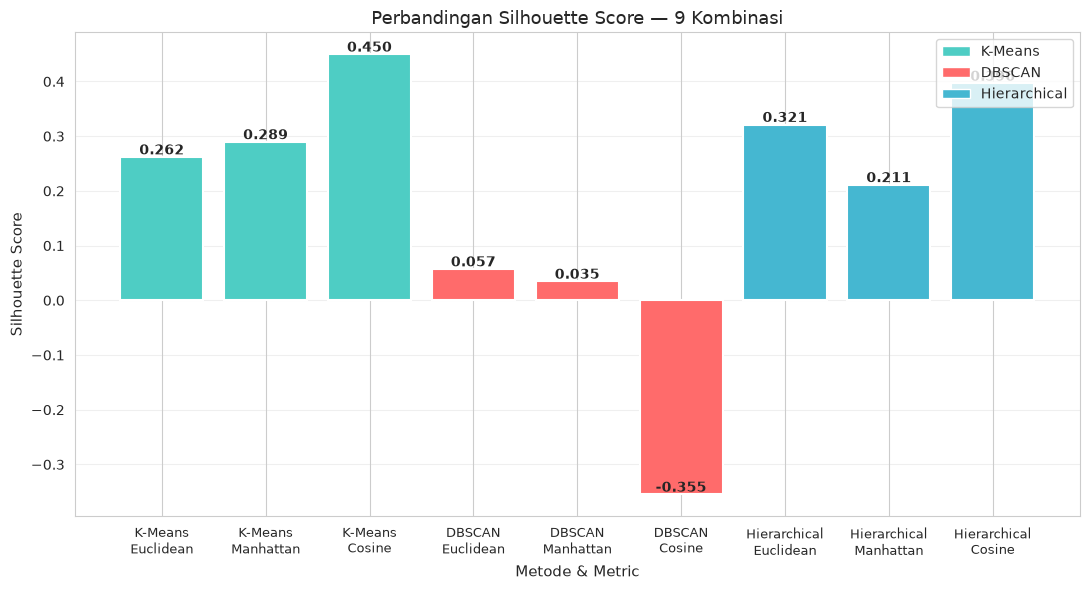

In [7]:
# Gabungkan label untuk sumbu x
df_hasil['Label'] = df_hasil['Metode'] + '\n' + df_hasil['Metric']

plt.figure(figsize=(11, 6))
colors = ['#4ECDC4']*3 + ['#FF6B6B']*3 + ['#45B7D1']*3
bars = plt.bar(df_hasil['Label'], df_hasil['Silhouette'],
               color=colors, edgecolor='white', linewidth=1.5)

# Tambah nilai di atas bar
for bar, val in zip(bars, df_hasil['Silhouette']):
    if val is not None:
        plt.text(bar.get_x() + bar.get_width()/2, val + 0.005,
                 f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.xlabel('Metode & Metric', fontsize=11)
plt.ylabel('Silhouette Score', fontsize=11)
plt.title('Perbandingan Silhouette Score — 9 Kombinasi', fontsize=13)
plt.xticks(rotation=0, fontsize=9)
plt.grid(True, alpha=0.3, axis='y')

# Legend manual
from matplotlib.patches import Patch
legend_elems = [Patch(facecolor='#4ECDC4', label='K-Means'),
                Patch(facecolor='#FF6B6B', label='DBSCAN'),
                Patch(facecolor='#45B7D1', label='Hierarchical')]
plt.legend(handles=legend_elems, loc='upper right')

plt.tight_layout()
plt.show()

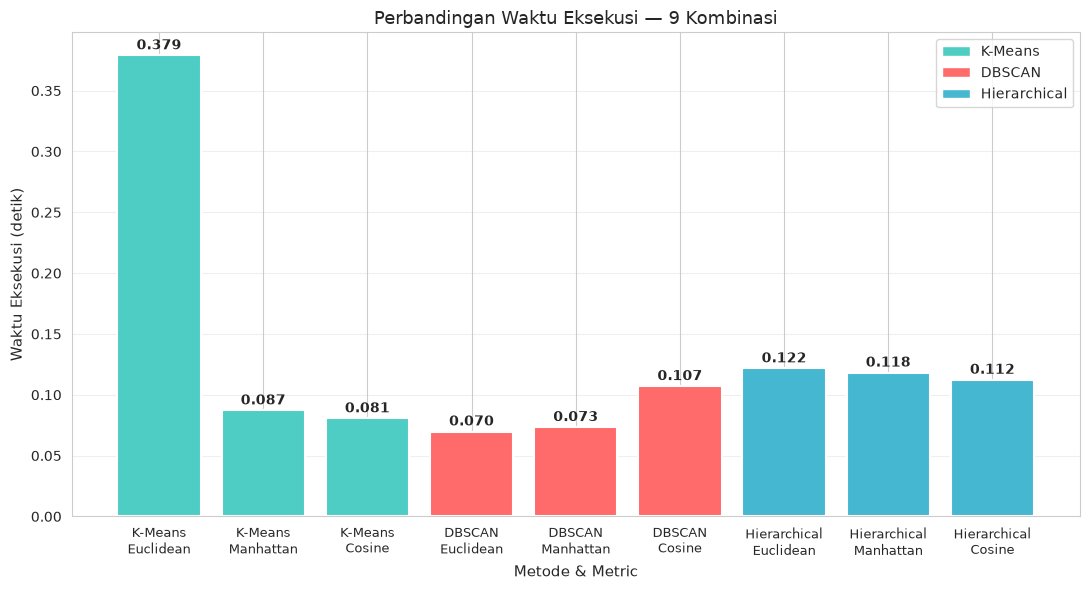

In [8]:
plt.figure(figsize=(11, 6))
bars = plt.bar(df_hasil['Label'], df_hasil['Waktu (s)'],
               color=colors, edgecolor='white', linewidth=1.5)

for bar, val in zip(bars, df_hasil['Waktu (s)']):
    plt.text(bar.get_x() + bar.get_width()/2, val + 0.005,
             f'{val:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.xlabel('Metode & Metric', fontsize=11)
plt.ylabel('Waktu Eksekusi (detik)', fontsize=11)
plt.title('Perbandingan Waktu Eksekusi — 9 Kombinasi', fontsize=13)
plt.xticks(rotation=0, fontsize=9)
plt.grid(True, alpha=0.3, axis='y')
plt.legend(handles=legend_elems, loc='upper right')
plt.tight_layout()
plt.show()

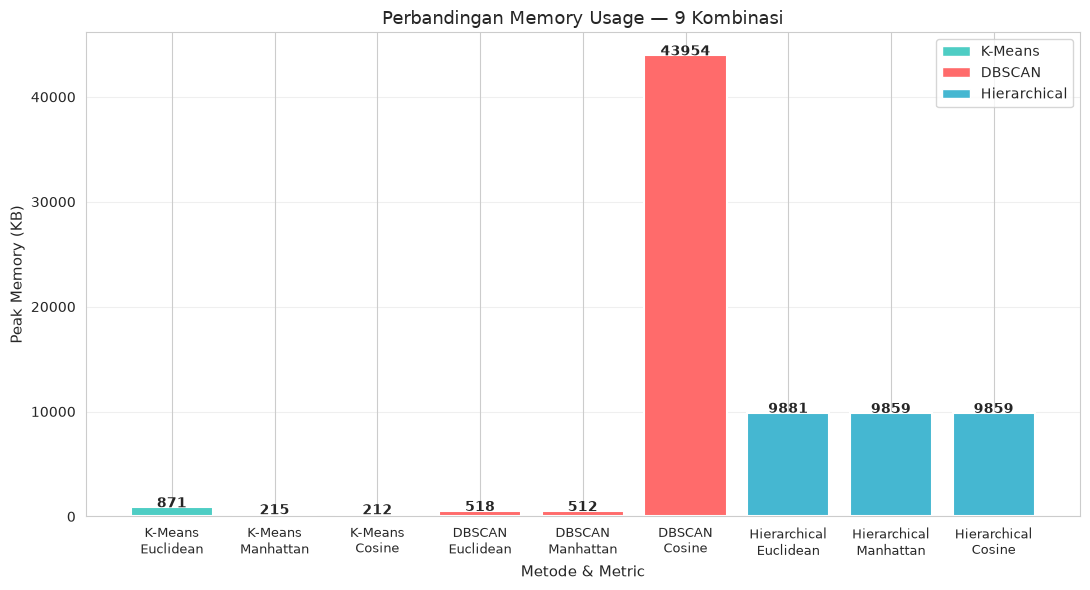

In [9]:
plt.figure(figsize=(11, 6))
bars = plt.bar(df_hasil['Label'], df_hasil['Memory (KB)'],
               color=colors, edgecolor='white', linewidth=1.5)

for bar, val in zip(bars, df_hasil['Memory (KB)']):
    plt.text(bar.get_x() + bar.get_width()/2, val + 3,
             f'{val:.0f}', ha='center', fontsize=10, fontweight='bold')

plt.xlabel('Metode & Metric', fontsize=11)
plt.ylabel('Peak Memory (KB)', fontsize=11)
plt.title('Perbandingan Memory Usage — 9 Kombinasi', fontsize=13)
plt.xticks(rotation=0, fontsize=9)
plt.grid(True, alpha=0.3, axis='y')
plt.legend(handles=legend_elems, loc='upper right')
plt.tight_layout()
plt.show()

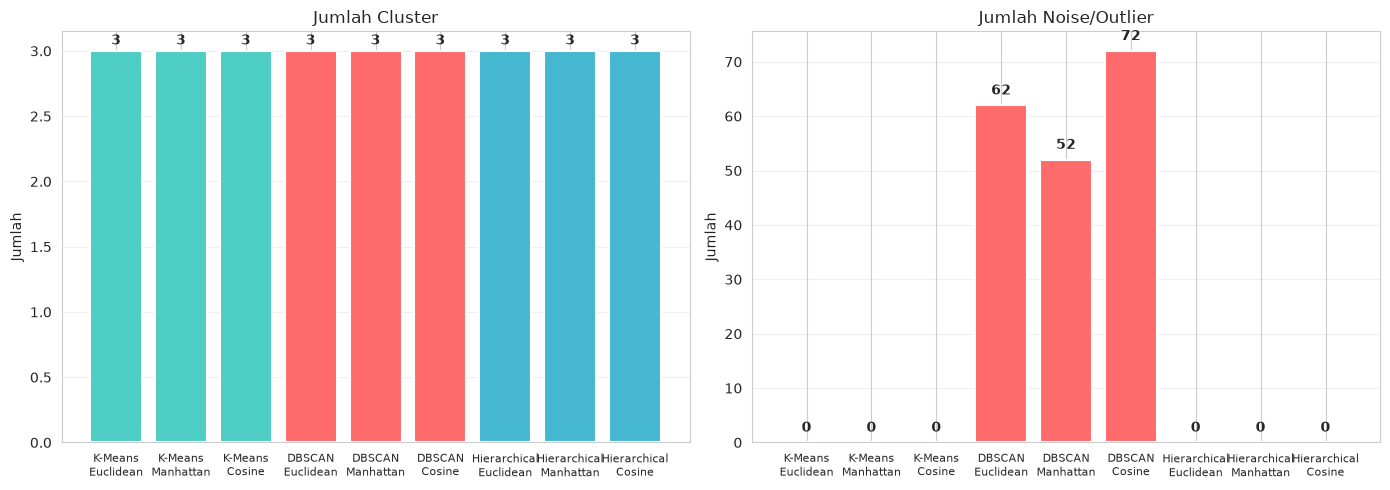

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Jumlah Cluster
bars1 = axes[0].bar(df_hasil['Label'], df_hasil['Jumlah Cluster'],
                    color=colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars1, df_hasil['Jumlah Cluster']):
    axes[0].text(bar.get_x() + bar.get_width()/2, val + 0.05,
                 str(val), ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Jumlah Cluster', fontsize=12)
axes[0].set_ylabel('Jumlah', fontsize=10)
axes[0].tick_params(axis='x', labelsize=8)
axes[0].grid(True, alpha=0.3, axis='y')

# Jumlah Noise
bars2 = axes[1].bar(df_hasil['Label'], df_hasil['Jumlah Noise'],
                    color=colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars2, df_hasil['Jumlah Noise']):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 2,
                 str(val), ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Jumlah Noise/Outlier', fontsize=12)
axes[1].set_ylabel('Jumlah', fontsize=10)
axes[1].tick_params(axis='x', labelsize=8)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

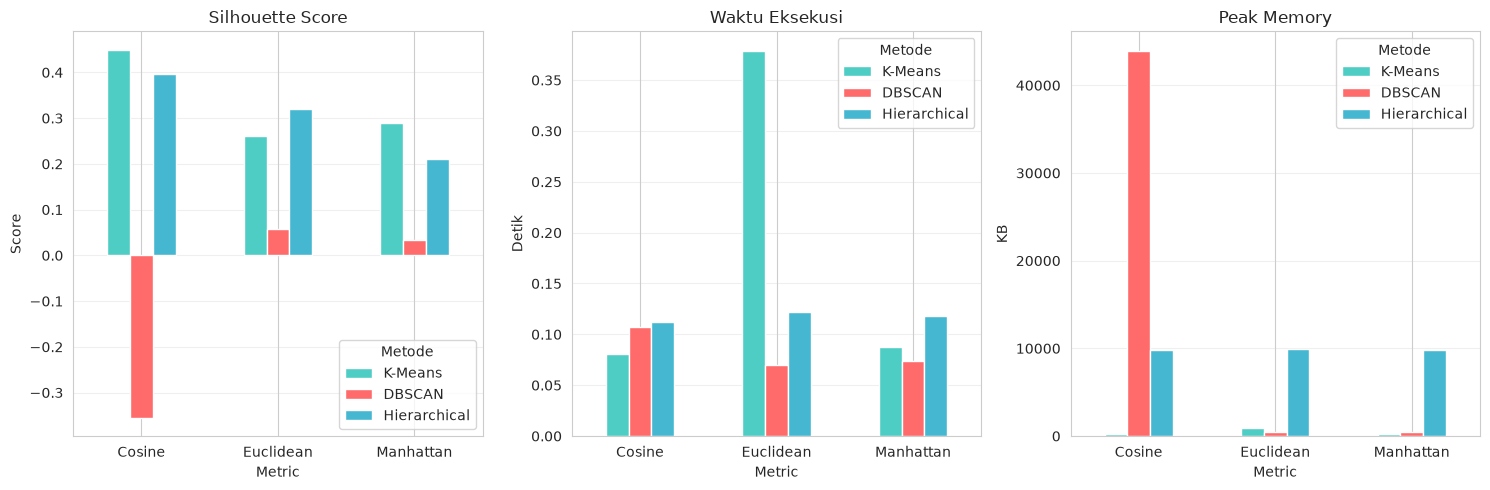

In [11]:
# Pivot untuk grouped bar
METODE_ORDER = ['K-Means', 'DBSCAN', 'Hierarchical']
WARNA = ['#4ECDC4', '#FF6B6B', '#45B7D1']

pivot = df_hasil.pivot(index='Metric', columns='Metode', values='Silhouette')[METODE_ORDER]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Silhouette
pivot.plot(kind='bar', ax=axes[0], color=WARNA, edgecolor='white')
axes[0].set_title('Silhouette Score', fontsize=12)
axes[0].set_ylabel('Score', fontsize=10)
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(True, alpha=0.3, axis='y')

# Waktu
pivot_w = df_hasil.pivot(index='Metric', columns='Metode', values='Waktu (s)')[METODE_ORDER]
pivot_w.plot(kind='bar', ax=axes[1], color=WARNA, edgecolor='white')
axes[1].set_title('Waktu Eksekusi', fontsize=12)
axes[1].set_ylabel('Detik', fontsize=10)
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(True, alpha=0.3, axis='y')

# Memory
pivot_m = df_hasil.pivot(index='Metric', columns='Metode', values='Memory (KB)')[METODE_ORDER]
pivot_m.plot(kind='bar', ax=axes[2], color=WARNA, edgecolor='white')
axes[2].set_title('Peak Memory', fontsize=12)
axes[2].set_ylabel('KB', fontsize=10)
axes[2].tick_params(axis='x', rotation=0)
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [12]:
df_hasil.to_csv('hasil_perbandingan_9_metode.csv', index=False)
print("Tabel disimpan ke 'hasil_perbandingan_9_metode.csv'")

Tabel disimpan ke 'hasil_perbandingan_9_metode.csv'


## Kesimpulan

**Fair comparison tercapai** — seluruh 9 kombinasi (3 metode × 3 distance metric) menghasilkan **jumlah cluster yang sama (3)**, sehingga metrik evaluasinya bisa dibandingkan secara adil:

| Metode | Parameter kunci | Alat pemilihan |
|---|---|---|
| K-Means | `k=3` | Elbow Method |
| DBSCAN | `min_samples=4` (konsisten), `eps` per metric | K-Distance Graph + tuning eps |
| Hierarchical | `n_clusters=3`, `linkage='average'` | Dendrogram |

**Hasil pengamatan:**

1. **Kualitas cluster (Silhouette Score):** K-Means dengan **cosine** terbaik (±0.45), disusul Hierarchical cosine (±0.40). DBSCAN jauh lebih rendah — wajar, karena DBSCAN memisahkan noise dan data ini memang padat menyatu sehingga jarak antar-cluster tipis.
2. **Efisiensi waktu:** semua metode < 0.5 detik; K-Means dan DBSCAN paling cepat.
3. **Efisiensi memory:** K-Means paling hemat (ratusan KB). Hierarchical butuh ±10 MB dan DBSCAN-cosine ±44 MB karena keduanya menghitung matriks jarak antar-titik.
4. **Noise:** hanya DBSCAN yang menandai noise (52–72 data, ±3.5–4.8%) — data yang tidak cukup padat untuk masuk cluster manapun.

**Rekomendasi akhir:** untuk dataset properti ini, **K-Means dengan cosine distance** memberikan keseimbangan terbaik antara kualitas cluster, kecepatan, dan pemakaian memory.